# BERT &mdash; Basics

**BERT (Bidirectional Encoder Representations from Transformers)** is a language model introduced by Google in 2018. It is built from a stack of Transformer encoder layers and pre-trained on large amounts of unlabeled text using self-supervised objectives: Masked Language Modeling (MLM), which recovers randomly hidden words from their surrounding context, and Next Sentence Prediction (NSP), which judges whether two segments are adjacent. Both are proxy tasks. Their purpose is not to predict masked words or sentence order, but to force the network to learn rich representations of language as a by-product.

The key outcome is **contextual word embeddings**. Earlier methods such as Word2Vec assign each word a single static vector, so a word like *"bank"* has the same representation in *"river bank"* and *"bank account"*. BERT instead computes a representation for each token that depends on the entire sentence, using self-attention over both left and right context. This brings the **Distributional Hypothesis** into the model itself: a word's meaning is determined by the company it keeps, and the representation changes with that company. Contextual embeddings handle ambiguity, syntax, and long-range dependencies far better than static ones, and they can be reused for many tasks, either as features for other models or by fine-tuning the pretrained encoder with a small task-specific head on limited labeled data. This **pretrain-then-fine-tune paradigm** substantially improved results on tasks such as text classification, natural language inference, named entity recognition, and question answering.

This is why it is important to learn about BERT. It marked a turning point in NLP and shaped the field that followed: many later models (RoBERTa, ALBERT, DistilBERT, ELECTRA, and others) are variants of BERT, and its core ideas of self-supervised pre-training, contextual embeddings, special-token input formats, and transfer learning carry over to modern language models. Understanding BERT gives a clear and manageable entry point into the Transformer architecture and into how large language models learn from text. This notebook introduces BERT on a conceptual level, and prepares the ground for training one from scratch and fine-tuning it on real tasks in subsequent notebooks.

### Setting up the Notebook

#### Make Required Imports

This notebook requires the import of different Python packages but also additional Python modules that are part of the repository. If a package is missing, use your preferred package manager (e.g., [conda](https://anaconda.org/anaconda/conda) or [pip](https://pypi.org/project/pip/)) to install it. If the code cell below runs with any errors, all required packages and modules have successfully been imported.

In [1]:
import numpy as np
import torch
from transformers import (
    BertTokenizer, 
    BertModel,
    BertForMaskedLM,
    pipeline
)
from transformers.utils import logging
from sklearn.metrics.pairwise import cosine_similarity

from src.utils.plotting.bert import *
from src.utils.compute.gpu import *

#### Checking & Setting Computing Device

PyTorch allows to train neural networks on supported GPU to significantly speed up the training process. If you have a support GPU, feel free to utilize it. However, for this notebook it's certainly not needed as our dataset is small and our network model is very simple. We provide an auxiliary method to automatically select the best device. It checks if a supported GPU is available and if so, uses it as the preferred device.

In [2]:
# Select preferred device (GPU, if available; CPU otherwise); you can enfore the use of the CPU
DEVICE = select_device(force_cpu=False)

print("Available device: {}".format(DEVICE))

Available device: cuda:0


#### Preliminaries

While there are brief recap, this notebook assumes a basic understanding of
* Word embeddings in general (i.e., the overall purpose and alternative methods such as Word2Vec or ELMo)
* The transformer architecture, including the attention mechanisms, positional encodings, as well as attention and loss masking

---

## Motivation & Overview

### The Need for Word Embeddings

Neural networks are, at their core, functions on numbers. They take fixed-size numerical vectors as input, apply differentiable operations such as matrix multiplications and nonlinearities, and produce numerical outputs. Everything that makes them trainable, including gradients, smooth optimization, and generalization from similar inputs to similar outputs, depends on the input living in a space where "close" and "far" mean something.

Language does not arrive in this form. Words and other tokens are *nominal* data: discrete symbols with no intrinsic geometry. For example, the two strings *"cat"* and *"kitty"* are arguably semantically near-synonyms, yet as character sequences they share almost nothing, while *"cat"* and *"cap"* differ by only a single letter and are unrelated in meaning. Surface form is therefore a poor guide to meaning, and any notion of similarity computed directly on strings, such as edit distance, would mislead a model.

We therefore need to convert tokens into dense, fixed-size, real-valued vectors, called **word embeddings** (or word embedding vectors or just embeddings), in a way that encodes semantics. The goal is that geometric relationships between vectors, such as cosine similarity or Euclidean distance, reflect semantic relationships between the corresponding words. If this holds, *"cat"* and *"kitty"* land near each other, *"cap"* lands far away, and a model that has learned something about one word can transfer that knowledge to its neighbors. The central question is how to learn such embeddings from data, and BERT embeddings based on the Transformer architectures are some of the most prominent ones.

### Distributional Hypothesis

There are many ways to compute word embeddings &mdash; as we will briefly outline in the recap section &mdash but they share a common foundation: they all implement the **Distributional Hypothesis**, which states that words occurring in similar contexts tend to have similar meanings. It is often summarized by Firth's slogan, *"You shall know a word by the company it keeps"*. The idea is that we do not need a dictionary or hand-crafted semantic annotations to learn what a word means. The statistical pattern of the words surrounding it, aggregated over a large corpus, already acts as a fingerprint of its meaning. Consequently, two words with similar fingerprints should receive similar vectors.

Consider the words *"cat"* and *"kitty"* and how they are used in the following example sentences:

- *"The cat curled up on the sofa and purred."*
- *"The kitty curled up on the sofa and purred."*
- *"We adopted a cat from the shelter."*
- *"We adopted a kitty from the shelter."*
- *"My cat chased a mouse and then slept."*
- *"My kitty chased a mouse and then slept."*

In other words, even if you would have never heard about a "cat" or a "kitty", just the way they are used in similar contexts, you could tell that these two words likely mean something very similar.

In a large corpus, both words will repeatedly co-occur with context words like *"purred"*, *"sofa"*, *"adopted"*, *"shelter"*, *"mouse"*, *"fur"*, and *"meowed"*. An embedding method turns this observation into geometry. Whatever its specific algorithm &mdash; maybe BERT or some other approach &mdash; it assigns vectors so that words with overlapping context distributions end up close together. In the end, *"cat"* and *"kitty"* receive nearby vectors, not because anyone told the model they are synonyms, but because the data showed them appearing in interchangeable contexts. The approaches differ mainly in *how* they extract and compress these contextual regularities into dense vectors, which is what the following section explores.

---

## Quick Recap & Prerequisites

### Word Embeddings

On a fundamental level, word embeddings are vector representations of words or tokens. However, apart from the algorithms learning those vectors, we can categorize word embeddings with respect to two main dimensions:

* **Sparse vs. dense embeddings.** Sparse embeddings have one dimension per vocabulary entry or context word, with most entries zero. Examples are one-hot vectors and raw co-occurrence count vectors (or their PMI-weighted variants). They are easy to interpret, since each dimension corresponds to a concrete word, but their dimensionality scales with the vocabulary, often reaching tens or hundreds of thousands. In contrast, dense embeddings instead use a small, fixed number of dimensions (typically 50 to 1,000), where almost every entry is nonzero and no single dimension has an obvious meaning. Nowadays, they are usually obtained by training neural network models.

* **Static vs contectual embeddings.** Static embeddings assign each word type exactly one vector, regardless of where it appears. The vector is learned once and stored in a lookup table. This is simple, cheap, and works well for capturing general word similarity, such as *"cat"* and *"kitty"*. Its weakness is that it conflates all senses of a word into a single point. For example, the word *"bank"* receives the same vector in *"She sat on the river bank"* and *"He deposited cash at the bank"*, even though the meanings differ. The vector ends up as a blend of its senses, weighted by their frequency in the training corpus. Contextual embeddings resolve this by computing the vector for a token as a function of the entire surrounding sentence. As a result same word yields different vectors in different contexts. *"Bank"* near *"river"* and *"bank"* near *"cash"* end up in different regions of the embedding space. 

For neural network inputs, dense embeddings are the standard choice. A sparse vector of vocabulary size would require a huge input layer, with parameters growing linearly in the vocabulary and most of them rarely updated. Dense vectors keep the input layer small and the computation cheap. Because they compress many correlated contexts into a few shared dimensions, they also let related words like *"cat"* and *"kitty"* share statistical strength, which helps the network generalize to words it has seen rarely. We therefore ignore sparse embeddings for any further dicussion and exclusively mean to dense embeddings from now own.

Contextual embeddings have become the dominant choice because they capture far more of what a word actually means in use. Because each word's or token's vector is computed from the entire surrounding text, it encodes the specific sense, grammatical role, and relationships to other tokens in that particular occurrence. The same word can land in different regions of the space depending on its use, so vector similarity reflects *contextual* semantic similarity rather than an average over all uses. Given their popularity, let's briefly outline some pre-BERT embeddings methods and discuss their strength and weaknesses, which BERT eventually aims to overcome.

#### Static Embeddings

One of the first prominent approaches to learn static embeddings was Word2Vec, introduced by Mikolov et al. (2013). In its core, Word2Vec is implemented as a word classification task where the goal is to train a model that can predict word relationships based on their contexts. The Word2Vec model can be implemented as a shallow neural network contain one hidden layer &mdash; represented by input weight matrix $\mathbf{U}$ &mdash; and one output layer &mdash; represented by input weight matrix $\mathbf{V}$ &mdash; This classification setup is essential because it enables Word2Vec to learn **semantic word embeddings** indirectly through prediction. By training to correctly classify words in context, the model adjusts its internal word vectors, captured by $\mathbf{U}$ and $\mathbf{V}$ so that words appearing in similar contexts have similar representations. Thus, while Word2Vec’s ultimate goal is not classification per se, framing it as such provides a simple and effective learning objective for capturing the statistical structure of language.

While there are different model implementations of Word2Vec typically focusing on improving efficiency, the two fundamental architectures of Word2Vec are **Continuous Bag-of-Words (CBOW)** and **Skip-gram**. The CBOW model takes as input a set of context words (typically words within a fixed window around the target) and aims to predict the center word. The "bag-of-words" term refers to the fact that the order of context words is ignored; only their presence matters. For example, in the sentence *"we were watching funny movies on netflix last weekend"*, if the window size is 2 and the target word is *"movies"*, the context words would be *"watching"*, *"funny"*, *"on"*, and *"netflix"* (again, CBOW ignores the actual order). For this example, the training sample might look as follows — keep in mind that the order of the context words does not matter, even when shown as a list here:

> ([*"watching"*, *"funny"*, *"on"*, *"netflix"*], *"movies"*)

In terms of architecture, CBOW uses a shallow neural network with one hidden layer. Each input context word is represented as a one-hot vector, which is mapped to its embedding vector via the input weight matrix. These embedding vectors are then averaged (or summed) to form a single context representation, which is passed through the output layer to predict the probability distribution over all words in the vocabulary. The model is trained to maximize the probability of the correct target word given the context words. The figure below illustrates the overall CBOW architecture.

<img src="images/illustrations/word2vec/word2vec-cbow-setup.png" style="margin:auto;max-width:800px;width:100%" alt="Word2Vec - CBOW" />

Notice that each word is associated with two distinct vector representations: an input embedding in $\mathbf{V}$ and an output (target) embedding in $\mathbf{U}$. As a result, the models learn two embedding matrices, reflecting the asymmetric roles words play when they appear as predictors versus prediction targets. After training, several strategies exist to obtain a single embedding per word. The most common approach is to discard the output embeddings and keep only the input embeddings, which empirically work well for many downstream tasks. Alternatively, one can use only the output embeddings, or combine both vectors, for example by averaging or concatenating them, to capture information from both roles. In practice, the choice depends on the task, but using the input embeddings alone has become the de facto standard due to its simplicity and strong performance.

But again, Word2Vec learns exactly one embedding vector per word or token in the vocabulary. Once training is finished, the learned weights are stored as a lookup table of shape $(\text{vocab\_size} \times \text{embed\_size}$), and each word is mapped to its row in that table. Because the vector depends only on the word's identity and not on the sentence it appears in, every occurrence of a word receives the same embedding. *"Bank"* in *"river bank"* and *"bank"* in *"bank account"* are mapped to the identical vector. Word2Vec nonetheless captures the Distributional Hypothesis well for general word similarity: *"cat"* and *"kitty"* end up close together because they share contexts. Its single-vector-per-word design is both its strength (simplicity, speed, a compact table that is easy to reuse as a network's input layer) and its main limitation, which contextual models were later developed to overcome.

#### Contextual Embeddings

ELMo (Embeddings from Language Models) is a deep contextualized word embedding approach that represents words as functions of the entire input sentence rather than as fixed vectors. Unlike static embeddings such as Word2Vec, ELMo captures how a word's meaning changes depending on its surrounding words. It does so by training a deep bidirectional language model (biLM) that reads text both left-to-right and right-to-left, allowing it to model rich syntactic and semantic information at multiple levels. ELMo trains a RNN-based language model based on the next-word prediction task using a self-supervived setup: the target sequence of a training sample is the same as the input sequence only shifted to the left by $1$ token. As the concrete RNN architecture, the original ELMo model uses a bidirectional LSTM (Long Short-Term Memory) network with $2$ layers. The figure below illustrates the overall setup:

<img src="images/illustrations/elmo/elmo-training-setup.png" style="margin:auto;max-width:800px;width:100%" alt="ELMo - Training Setup" />

<br />

Using a bidirectional LSTM allows ELMo to construct word representations that depend on both left and right context, which is crucial for capturing how meaning varies with usage. Many words are ambiguous when viewed from only one direction (e.g., *"bank"*, *"charge"*), and relying solely on past context can be insufficient to disambiguate them. By combining a forward LSTM that summarizes preceding words with a backward LSTM that summarizes following words, ELMo produces embeddings that encode richer syntactic and semantic information, such as long-range dependencies, agreement, and phrase-level structure. This bidirectional context is especially beneficial for downstream tasks like named entity recognition or question answering, where cues often appear after the word being interpreted. 

After training, ELMo embedding $\mathbf{e}_t$ for the $t$-th word in an input sequence is not taken from a single layer or a single vector table, but are constructed dynamically as "some" combination of the internal hidden states of model, sometimes including the uncontextualized embedding $\mathbf{h}_t^{(0)}$ (i.e., the initial embedding that serves as input for the first LSTM layer). In other words, getting the embedding for a word or token is no longer just a quick look up like or static embeddings but requires passing the word and its surrounding context (e.g., the sentence or paragraph) to be passed to the model.

While ELMo builds contextual embeddings with stacked bidirectional LSTMs, its reliance on RNNs brings several limitations. Tokens must be processed one at a time, which prevents parallelization and makes training on large corpora slow. Information from distant tokens has to pass through many recurrent steps, so long-range dependencies are hard to capture despite LSTM gating, and the fixed-size hidden state acts as a bottleneck. Its bidirectionality is also shallow: separate left-to-right and right-to-left models are trained independently and concatenated, so no layer conditions jointly on both sides of a token. Finally, ELMo is typically used as a frozen feature extractor feeding a task-specific model rather than being fine-tuned end to end. These weaknesses motivated the Transformer, whose self-attention links all positions directly and computes them in parallel.

### Transformer Architecture

BERT's defining architectural choice is that it is built on the Transformer encoder rather than on recurrent networks. This is the source of most of its advantages over ELMo: every token can attend directly to every other token in a single layer, the whole sequence is processed in parallel, and each layer conditions on left and right context simultaneously, which makes the model *deeply* bidirectional rather than a concatenation of two one-directional models. The parallelism also makes it practical to pretrain very large models on very large corpora, and to fine-tune the entire network end to end on downstream tasks. To understand how BERT produces its contextual embeddings, it therefore helps to first review a few core mechanisms of the Transformer.

The figure below is taken from original Transformer paper [*"Attention is all you Need"*](https://arxiv.org/abs/1706.03762) and  shows the overall Transformer architecture. The (full) Transformer is an encoder-decoder architecture. In a nutshell, using a machine translation task as an example, purpose of the **encoder** is to read and understand the input sentence in the source language and convert it into a rich, contextualized representation (i.e., embedding vectors!). The **decoder** then generates the output &mdash; here: the translated sentence in the target language &mdash; one word at a time, using the contextual information provided by the encoder. The decoder takes the encoder's output and combines it with the previously generated target word to predict the next word in the translation.

<img src="images/illustrations/transformer/transformer-architecture-paper.png" style="margin:auto;max-width:500px;width:100%" alt="Transformer Architecture" />

<br />

The original Transformer was designed for sequence-to-sequence tasks such as machine translation, but BERT's goal is different: it does not generate text but *represents* it. We want one vector per input token that captures the token's meaning in context, which can then be used for classification, tagging, question answering, or similarity. For this purpose, the decoder is unnecessary; there is no target sequence to produce. The output of the final layer is exactly what we want: a sequence of contextualized embedding vectors, one per input token. Dropping the decoder also roughly halves the architecture, which makes the model simpler and cheaper to train and lets the same parameter budget go into a deeper or wider encoder.

Before we actually see how BERT embeddings are learned, let's briefly recap the core components of Transformers &mdash; well, of the encoder anyway &mdash; to see how the architecture works. Not only helps this understanding the ideas and intuition behind BERT but also highlights why this or similar Transformer-based approaches typically outperform RNN-based alternatives such as ELMo.

### Attention

The a heart and soul of the Transformer architecture is the **attention mechanism** (or attention or attention head). On a very high level, an attention head is a network component that takes in a sequence of (initial static) embedding vectors and returns a sequence of recalculated embedding vectors. The figure below illustrates this idea of an attention:

<img src="images/illustrations/attention/attention-core-idea-extended.png" style="margin:auto;max-width:800px;width:100%" alt="Attention Head (Conceptual Idea)">

<br />

In this example, the input sentence contains three occurrences of the word *"light"* but three very different meanings. The attention now recalculates each occurrence's embedding vector so that it is more likely to capture its specific semantics given the context of the sentence. As such, the three output embedding vectors are likely to be quite different. Note that the embedding vectors for all the words will be recalculated, but the figure only highlights this idea for the three occurrences of the word *"light"*.

In general, an attention head (i.e., a single attention computation) aims to capture syntactic relationships (e.g., subject-verb agreement, modifiers and what they modify) and semantic relationships (e.g., coreference resolution, synonyms or paraphrases) between words. This includes that even the same pair of words may form different relationships. To capture different types of such relationships in parallel, the Transformer architecture employs more than one attention head in parallel for the same input sequence(s). All parallel attention heads are combined into a single network layer called **multi-head attention**. The figures below visualizes this idea combining 3 attention heads into a multi-head attention layer.

<img src="images/illustrations/attention/multi-head-attention-core-idea.png" style="margin:auto;max-width:800px;width:100%" alt="Multi-Head Attention (Conceptual Idea)">

<br />

Despite having multiple attention heads, the output of the multi-head attention layer is still a single recalculated embedding vector for each input word. This is done by combining the outputs of all attention heads. How this and all other involved operations are done is the subject of the next section.

The important part is of course how this recalculation for input embeddings is done. Since the math underpinning attention is beyond the scope of this notebook, the fundamental idea is as follows: each output embedding is the **weighted sum** of all input embeddings, and the weights derived from the alignment (a similarity scores based on the dot product) between **all pairs** of input embeddings. To this end, each embedding of the input sequence gets transformed into a so-called query (Q), key (K), and value (V) space using learnable weight matrices $\mathbf{W}_q$, $\mathbf{W}_k$, and $\mathbf{W}_v$. The figure below illustrates this step assuming a sequence of $4$ embedding vectors of size $12$:

<img src="images/illustrations/attention/attention-encoder-self-attention-qkv-transformation.png" style="margin:auto;max-width:800px;width:100%" alt="Self-Attention: QKV Transformation">

Given $\mathbf{Q}$, $\mathbf{K}$, and $\mathbf{V}$, the output embeddings are computed as shown below. In a nutshell, $\mathbf{Q}\mathbf{K}^\top$ first computes the dot products between the query and key vectors, and the $\text{Softmax}$ function normalizes the result such that all rows sum up to $1$; the scaling factor $1/\sqrt{d_k}$ "only" important for computational reasons (and less for the concept of attention itself). Multiplying this result with all value vectors gives us what we want: the output where each embedding is a weighted sum of all value vectors &mdash; which, recall, were derived from the input embeddings via a linear transformation.

<img src="images/illustrations/attention/attention-encoder-self-attention-full.png" style="margin:auto;max-width:1000px;width:100%" alt="Self-Attention in Decoder">

<br />

Note that the attention mechanism itself, meaning the dot products between queries and keys, the scaling, the softmax, and the weighted sum over values, has no learnable parameters. All the learning happens in the linear projections around it. This includes the three transformation matrices $\mathbf{W}_q$, $\mathbf{W}_k$, and $\mathbf{W}_v$ of each attention head, as well as a single output matrix $\mathbf{W}_o$ that combines the concatenated outputs of all heads, mixing the information from the different heads.

### Masking

By default, attention compares each token's query with each token's key in the sequence. But sometimes we need to ignore certain inputs. The most common case is batching. To process several sequences at once with matrix operations, all sequences in a batch must have the same length, so shorter ones are padded with a special `[PAD]` token up to the length of the longest. The padding tokens carry no information, so any alignment between a real token and a padding token is meaningless. If we left them in, the softmax would assign some of its attention weight to `[PAD]` positions, and the output vectors of real tokens would be contaminated by irrelevant content. Worse, the result for a given sentence would then depend on how much padding happened to be added, which in turn depends on what other sentences share its batch.

The figure below shows an example of what would happen if we ignore padding tokens. In this example, we assume that the longest sequence has a length of $5$, and any sequence longer than that gets padded with `[PAD]`. However, when computing $\mathbf{Q}\mathbf{K}^\top$ we treat `[PAD]` as a normal token. As a consequence, the final output embeddings would also depend on the attention between normal and padding tokens. This is obviously not meaningful.

<img src="images/illustrations/masking/masking-padding-attn-score-calc.png" style="margin:auto;max-width:750px;width:100%" alt="Padding Mask: Calculating Attention Scores">

The solution is an **attention mask**. Before the softmax, the scores for all pairs involving a padding position are set to a very large negative number (effectively −∞), so the softmax assigns them a weight of essentially zero. The padded tokens then contribute nothing to the weighted sum over values, and real tokens attend only to other real tokens. The padded positions still produce output vectors, but these are simply discarded or excluded from the loss. The figure below illustrates the effect of the attention mask.

<img src="images/illustrations/masking/masking-padding-attn-weights-calc.png" style="margin:auto;max-width:650px;width:100%" alt="Padding Mask: Attention Weights Calculation">

<br />

Apart from attention masking to handle padded inputs, BERT also relies on **loss masking**. Loss masking controls which parts of the output contribute to the training loss. When a model makes predictions over a sequence &mdash; such as words in a sentence &mdash; not every position may contain meaningful information for learning. Loss masking ensures that only the relevant positions are considered during loss computation, while the rest are excluded. Most obviously, we also want to ignore padding tokens when computing the loss. However, particularly for BERT, we also want to exclude the loss for some normal tokens, i.e., non-padding tokens. Why we want this we will of course discuss in full detail in this notebook.

### Architecture (Encoder-Only)

We already saw that the full Transformer is an encoder-decoder architecture. However, BERT only uses the encoder to learn contextual word embeddings, and can therefore ignore the decoder part in this notebook. While attention is the core component of the Transformer it alone is not enough to build a deep, trainable sequence model. Self-attention is essentially a learned, input-dependent *weighted average* of value vectors. That is powerful for routing information between positions, but it has limitations that the other components address.

*  **Position-wise feedforward network (FFN) layer.** The attention output is a linear combination of the value vectors. Stacking attention layers alone would therefore add little expressive power. The feedforward network (typically: $\text{Lineat}$ $\rightarrow$ $\text{ReLU/GELU}$ $\rightarrow$ $\text{Linear}$) adds a genuine non-linear transformation. Also, attention mixes information *across* positions; the FFN processes each position *independently* and identically. This gives a division of labor: attention gathers context, the FFN transforms and "digests" it. And lastly, the FFN layer expands the dimension and adds capacity to the model in terms of learnable parameters; much of the model's learned knowledge is believed to be stored here.

* **Supporting components.** Residual connections, layer normalization, and dropout make deep Transformer stacks trainable. Residual connections $\mathbf{x} + \text{Sublayer}(\mathbf{x})$) give gradients a direct path through the network and let each sublayer learn a refinement of its input rather than a full transformation. Layer normalization standardizes each token's activations across the feature dimension, keeping them stable as depth increases and allowing faster, more reliable training. Dropout randomly zeroes activations during training, acting as regularization that reduces overfitting in these large, heavily parameterized models.

The figure below shows a single encoder layer with the attention mechanism and the additional components.

<img src="images/illustrations/transformer/transformer-encoder-layer-paper.png" style="margin:auto;max-width:200px;width:100%" alt="Transformer Architecture" />

<br />

An encoder layer maps an input of shape to an output of exactly the same shape. Because shapes are identical, encoder layers can be stacked freely: the output of layer *n* is directly the input of layer *n+1*, and the depth (e.g. 6 or 12 layers) becomes a simple hyperparameter. Each layer re-represents every token as a context-dependent mixture of the tokens it received, so the representations become progressively richer and more contextual as they pass up the stack. This stack of encoder layers forms the complete encoder of the Transformer architecture, and this is what the BERT model utilizes to learn contextual embeddings.

---

## Learning Objective

Every neural network turns its input into internal vector representations (embeddings) in order to solve some training task. These embeddings are a by-product of optimizing the **learning objective**, so what the embeddings capture depends on what the network was trained to do. Networks such as Word2Vec, ELMo, as well as BERT are specifically designed to yield general-purpose embeddings, i.e., embeddings that capture useful semantics and can therefore be used as meaningful inputs for other tasks and networks. 

Word2Vec, ELMo, as well as BERT (and other approaches) differ mainly in this objective. For example, Word2Vec (CBOW) predicts a word from its surrounding words within a window, ignoring word order. ELMo trains a bidirectional language model, where a forward RNN predicts the next word and a backward RNN predicts the previous word. In contrast, Transformer-based BERT combines two different learning objectives: **Masked Language Model (MLM)** and **Next Sentence Prediction (NSP)**. Both relate to the Distributional Hypothesis, although MLM does so much more directly. So let's look at both objectives in more detail.

### Masked Language Model (MLM)

In a nutshell, the MLM learning objective of BERT is a "recovery" task: hide some words or tokens and train the model to recover them. A standard left-to-right language model can only use the preceding words, whereas the masking lets the model use context from both sides at once, since the missing word is no longer visible to "see itself" through the surrounding tokens. To predict a masked word well, the network must understand syntax, semantics, and world knowledge expressed by the rest of the sentence, so these abilities are encoded in its internal representations.

This is a direct implementation of the Distributional Hypothesis, which states that a word's meaning is determined by the contexts in which it appears. MLM makes the model predict a word purely from its context, so words that occur in similar contexts must receive similar representations in order to produce similar predictions. Unlike Word2Vec, where each word gets one fixed vector, BERT computes the representation through deep, context-sensitive layers, so the same word can have different embeddings depending on its surroundings. The core procedure for the masking is as follows:

* Select about **15%** of the input tokens at random as prediction targets; the remaining **85%** of tokens remain unchanged
* Of those 15% selected tokens:
  * 80% are replaced with a `[MASK]` token,
  * 10% are replaced with a random token,
  * 10% are left unchanged.

To show an example, consider the following simple sentence:

> I watched a movie last night on an old DVD I found about a man who lost his memory.

We can now apply the procedure above, and let's assume we randomly pick the following four targets &mdash; which is a bit more than 15% of all tokens but it makes the example a bit more interesting.

| Target | Replacement rule | Result |
|---|---|---|
| `movie` | 80%: replace with `[MASK]` | `[MASK]` |
| `man` | 80%: replace with `[MASK]` | `[MASK]` |
| `DVD` | 10%: replace with a random token | `river` |
| `memory` | 10%: keep unchanged | `memory` |

As output, we get the following corrupted sequence:

> I watched a <font color="red"><b>[MASK]</b></font> last night on an old <font color="red"><b>river</b></font> I found about a <font color="red"><b>[MASK]</b></font> who lost his <font color="red"><b>memory</b></font>.

The MLM learning objective of BERT is now to predict these four targets. This means that the training loss is only computed at these positions. More specifically, assuming the $\tilde{x}$ denotes the corrupted input sequence, we compute the following cross-entropy loss:

$$\large
\mathcal{L} = -\big[\log P(\text{movie}\mid\tilde{x}) + \log P(\text{DVD}\mid\tilde{x}) + \log P(\text{man}\mid\tilde{x}) + \log P(\text{memory}\mid\tilde{x})\big]
$$

where, say, $P(\text{movie}\mid\tilde{x})$ is the probability the model assigns to the original token `movie` at the first `[MASK]` position, given the *entire* corrupted sequence $\tilde{x}$. Keep in mind that the model never sees the original sequence $x$ itself, only $\tilde{x}$, and it must reconstruct the original tokens at the selected positions from it. Note that $\tilde{x}$ differs from $x$ only at the selected positions; positions that were not selected are copied unchanged and contribute no loss term. We can use this example to better understand the intuition what each of the three cases teaches:

* `[MASK]` $\rightarrow$ `movie` and `[MASK]` $\rightarrow$ `man`: The contexts *"[...] watched a ___ last night [...]"* and *"[...] about a ___ who lost his memory"* suggest that *"movie"* and *"man"*, respectively, are suitable predictions which is the standard signal for the Distributional Hypothesis. Of course, other alternatives are also plausible. For example, for the context *"[...] watched a ___ last night [...]"*, word such as *"series"* or *"drama"* are also very likely. This shows that the model learns a probability distribution over candidates, not a single certain answer.
  
* `river` $\rightarrow$ `DVD`: The sequence *"[...] an old river I found [...]"* is arguably implausible. This teaches the model not to blindly trust the input token. Without them, a visible token that is not `[MASK]` would always be correct, and the model could simply copy it forward. With them, any visible token might be wrong, so the model has to check each one against its context.

* `memory` $\rightarrow$ `memory`: the token is correct, and the model must still predict it, so it learns not to assume visible tokens are never targets &mdash; remember that we do not touch 85% of the original input tokens and those tokens are not part of the loss. These tokens teach the model that a visible, real token can still be a prediction target; this has two main effects: 
    * **Representations of real tokens get trained.** At fine-tuning and inference time, every input is a real token, never `[MASK]`. If the loss were computed only at `[MASK]` and random-token positions, nothing would directly train the output representation of a genuine, uncorrupted word. The unchanged case supplies that signal: the model sees the true token `memory` and is rewarded for producing a representation from which `memory` can be recovered. This biases the representation of observed tokens toward the actual word, which is exactly what downstream tasks consume.
    * **It counters the shortcut "not `[MASK]` means not a target."** Without it, the model could learn two simple rules: at `[MASK]`, predict from context; elsewhere, don't worry about it. Because any visible token might be a target, the model must keep a good, context-aware representation at every position.

The model produces a prediction over the vocabulary at *every* position, but only the ~15% selected positions have a meaningful training target. For the other 85%, the input token is unchanged and is simply the original word, so asking the model to predict it would be trivial (copy the input) and would teach almost nothing. BERT therefore relies on **loss masking** (see above) to ignore all positions that have not been selected. Not that the 15% rate is a compromise: masking more leaves too little context to predict from, while masking less makes each sequence yield too little learning signal and slows training.

While the MLM learning objective uses loss masking, it does not apply any form of attention masking beyond handling padding tokens (see above). This means that we compute the attention weights between each `[MASK]` token and any other token. The `[MASK]` token already hides the information to be predicted. It carries no lexical content of its own (every `[MASK]` has the same input embedding, differing only by position), so its representation is built almost entirely from what it gathers via attention. Given the interpretation of query and key vectors as part of the attention mechanism, the `[MASK]` token plays the following roles:

* `[MASK]` as query vector: The attention weight from a `[MASK]` position to another token says how much that token's information is used to fill in the blank. High attention weights typically reflect syntactic cues (e.g., the determiner *"a"* in *"I watched a ___ last night [...]"* expects a noun), semantic & topical cues (e.g., *"watch"* in "I watched a ___ last night [...]" makes *"movie"* arguably more likely than "*table*").
* `[MASK]` as key vector: The attention weight from a token to `[MASK]` says how much that token depends on that missing position

To sum up, the MLM objective of BERT is to recover a corrupted input sequence. This is a direct implementation of the Distributional Hypothesis, since a word's identity must be inferred purely from the company it keeps, namely its left and right context. To do this well, the network has to learn representations in which words that occur in similar contexts behave similarly, and because the self-attention layers see the whole sequence, these representations are deeply bidirectional and context-dependent rather than static. This typically yields better embeddings compared to ELMo.

**Important:** Throughout the previous example, all tokens were complete words. However, most modern architectures &mdash; including BERT &mdash; rely on **subword tokenization** methods such as Byte-Pair Encoding or WordPiece. This means that a word such as *"unbeatable"* may be split into [*"un"*, *"beat"*, *"##able"*] (here we assume WordPiece, the tokenizer of the original BERT). There are two basic ways to handle subwords. The original BERT model treated subword individually, meaning that [*"un"*, *"[MASK]"*, *"##able"*]. However, later variants performed whole word masking (WWM) where all pieces of a selected words are masked together, e.g., [*"[MASK]"*, *"[MASK]"*, *"[MASK]"*]. Both approaches are valid; the table below briefly outlines the common pros and cons:

| Aspect | Individual subword masking (original BERT) | Whole Word Masking (WWM) |
|---|---|---|
| **Unit of selection** | Each WordPiece token is selected independently | A whole word is selected, and all its pieces are masked together |
| **Example** | `un [MASK] ##able` | `[MASK] [MASK] [MASK]` |
| **80/10/10 rule** | Applied per WordPiece | Applied per whole word |
| **Masking rate** | About 15% of WordPieces | About 15% of WordPieces (counted over whole words) |
| **Pros** | Simple to implement, with no word-boundary information needed beyond the tokenizer. Also trains the model to handle word-internal structure and morphology. | Harder, more meaningful task, since the word must be recovered from surrounding words. Closer to the Distributional Hypothesis, as the signal comes from sentence context. Generally gives slightly better downstream performance. |
| **Cons** | Often too easy: visible neighbor pieces (`un`, `##able`) almost determine the masked piece, so the model can use word-internal statistics instead of sentence context. This weakens the contextual learning signal. | Requires word-boundary information (e.g. from `##` markers). Masked pieces are still predicted independently of each other, and a rare long word can remove a large chunk of the input. A random replacement can also produce an odd mix of pieces. |

Both use the same loss and 15% rate. WWM only changes *which* tokens are hidden together, which makes the prediction task depend more on context and less on local spelling cues.

### Next Sentence Prediction (NSP)

The MLM objective is a direct implementation of the Distributional Hypothesis: a masked word must be inferred from the company it keeps. In practice, however, this signal is dominated by **local context**, i.e. a few words to the left and right of the masked position. A word's part of speech (noun, verb, adjective, etc.) and its morphology (tense, number, agreement) are determined almost entirely by its immediate neighbors, and almost certainly by the same sentence alone. Predicting such words requires no information from other sentences, so MLM mostly rewards learning syntax and local semantics, even though the attention mechanism could in principle look much further.

Many tasks, however, benefit from **explicitly capturing information shared across sentences**. Natural Language Inference (textual entailment) requires judging whether a hypothesis follows from a premise, and question answering requires relating a question to the passage that answers it. Both depend on how two segments relate to each other, which token-level MLM never directly trains. This gap motivate the addition of sentence-level learning objectives. BERT implements this idea by means of the Next Sentence Prediction (NSP) objective.

NSP is set up as a binary classification task: given to sentences `A` and `B`, the class label is $0$, if `B` directly follows `A` in the same document; and $1$ otherwise. For sentence pairs of class $1$, sentence `B` is typically taken from a different document to lower the probability that there is still some kind of semantic relationship between `A` and `B`. To give an example, here are two sentence pairs and their respective class labels.

> (*"I watched a movie last night."*, *"The special effects were all so cool."*, 0)<br />
(*"I watched a movie last night."*, *"It is often very cold in the winter."*, 1)

NSP turns the input into a **pair of segments** and asks for a **single sentence-pair-level prediction**. A plain token sequence offers neither a way to tell where one sentence ends and the next begins, nor a place from which to read off one label for the whole input. The two special tokens fill these gaps.

**`[SEP]` marks the segment boundary.** The model sees `sentence A [SEP] sentence B [SEP]` as one flat sequence, and since self-attention has no inherent notion of sentences, it needs an explicit delimiter to know where `A` ends and `B` begins. This is what allows the model to compare the two segments and decide whether `B` follows A. (BERT additionally adds learned segment embeddings that label each token as belonging to A or B &mdash; as we will see later &mdash; but `[SEP]` is what marks the boundary in the token sequence itself.) As an important side note, BERT needs `[SEP]` because punctuation is too ambiguous to serve as a segment boundary. A period can appear inside a segment (`Dr. Smith`, `3.14`), many segments end with no punctuation at all, and a BERT "segment" is often several sentences long, so ordinary punctuation marks the wrong level of structure. 

**`[CLS]` provides a sequence-level representation.** MLM yields one output vector per token, but NSP is a binary classification of the *whole pair*, so it needs a single vector to feed into the classifier. `[CLS]` is placed at the start of every input and has no lexical meaning of its own. Because it attends to all tokens in both segments, its final hidden state can aggregate information about the entire pair, and this vector is fed into the `IsNext`/`NotNext` classifier.

With this, for our two example sentence pairs, the respective inputs would look as follows &mdash; before we perform any masking of tokens.

> `[CLS] I watched a movie last night . [SEP] The special effects were all so cool . [SEP]`<br />
`[CLS] I watched a movie last night . [SEP] It is often very cold in the winter . [SEP]`

NSP was proposed as part of the original BERT model to give it a sentence-level training signal beyond token-level MLM: given two segments, the model predicts whether the second actually follows the first in the corpus or is a random segment. Later work showed that NSP often provides only a weak signal, since random negatives usually come from a different document and can be detected through simple topic cues. As a result, several BERT variants either drop NSP altogether (e.g. RoBERTa) or replace it with a harder alternative such as sentence order prediction (ALBERT). Here, however, we focus on the original BERT architecture, which includes NSP alongside MLM.

### Combined Setup

Combining the MLM and NSP learning objectives now fully describes the training setup of BERT, as illustrated in the figure below. The input at the bottom shows the masked sentence pair (including random replacement *"banana"* and the preserved token *"so"*) separated by `[SEP]` and preceded by the `[CLS]` token. Of course, the input sequence may also be followed by `[PAD]` tokens, particularly when dealing with batched input; we also omitted the punctuation marks to keep the figure a bit simpler. This input sequence is first fed into a collection of embedding matrices to convert the tokens into their initial embeddings &mdash; we discuss this step later in full detail.

The initial embeddings then pass through all encoder layers, each layer including the attention mechanism and the feedforward network (FFN) layer. The transformed embeddings of the last encoder are then fed into a classification head, i.e., a small network that eventually computes raw logits or the $\text{Softmax}$ probabilities for each output. While not shown here, the classification head for the `[CLS]` output looks typically a bit different then the head for all other tokens, but the overall purpose is the same.

<img src="images/illustrations/bert/bert-example-setup.png" style="margin:auto;max-width:900px;width:100%" alt="BERT - Example Setup" />

<br />

The output of the classification head is then used to compute the loss and therefore to eventually train the model. Notice that the figure above only shows the positions for which we compute the loss: the [CLS] token label (either $0$ or $1$) as well as the true tokens for the selected target tokens (masked, randomized, or preserved).

**Final embeddings.** After training a BERT model, the learned contextual embeddings are the **output vectors of the last encoder layer**. In practice, these final-layer vectors can be used as token-level embeddings, the `[CLS]` vector or a mean over tokens can serve as a sentence-level embedding, and the vectors can be fed to other models or to a task-specific head for fine-tuning. The final layer is not always the best choice for feature extraction: intermediate layers (or an average of the last few) sometimes work better, because the last layer is specialized toward the pre-training objective.

---

## Training Samples

Training BERT requires turning raw text into samples that serve two learning objectives at once while also matching what the Transformer architecture expects as input. For MLM, each sample must contain a corrupted token sequence together with labels that identify the original tokens at the selected positions. For NSP, it must contain a pair of segments and a label saying whether the second truly follows the first. On top of this, the Transformer needs fixed-shape numeric inputs: token IDs, segment IDs, position information, and an attention mask that hides padding. Preparing a single training sample therefore means combining these requirements into one consistent format, which is what this section shows step by step.


### Input Representation

In the previous section, we saw how input sentences are organized to match both the MLM and NSP learning objective. More specifically, we saw that BERT assumes as input pairs of sentences, with some tokens masked, as well as special tokens (`[CLS]`, `[SEP]`, and `[PAD]`) added. As a running example in the section, we consider the example input from the previous figure; we also add two `[PAD]` tokens just to cover all cases:

> `[CLS] I [MASK] a movie last banana [SEP] The special MASK were all so cool [SEP] [PAD] [PAD]`

Recall that `banana` stems from a random replacement, and `so` was a selected token that is preserved, both are used to compute the final loss. This string contains all the required information to create the initial encodings to serve as a valid input for the BERT encoder.

#### Vocabulary & Special Tokens

BERT represents each input position by three IDs, each looked up in its own embedding matrix. The three resulting vectors are summed to form the input to the first encoder layer; discussed later. These three types of IDs are:

* **Token ID:** the index of the WordPiece token in the vocabulary. It tells the model *which* token is at this position and selects the token embedding, which carries lexical meaning. Which ID refers to which token depends on the pretrained tokenizer. For example, using the `bert-base-uncased` tokenizer, the IDs for the special tokens are: `[CLS]` = $101$, `[SEP]` = $102$, `[MASK]` = $103$, `[PAD]` = $0$. Examples for "normal" tokens are `movie` = $3185$, `all` = $2035$, or `banana` = $15212$.
* **Segment ID:** indicates which segment the token belongs to:
    * $0$ for `[CLS]`, segment A and the first `[SEP]`
    * $1$ for segment B and the final `[SEP]`
* **Position ID:** the index of the token in the sequence ($0$, $1$, $2$, ...). It selects the position embedding, which is needed because self-attention has no built-in notion of word order.

The table below shows how each token in our example input string gets converted into these three types of IDs. The token IDs are the true values when using the pretrained `bert-base-uncased` tokenizer.

| Index | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| **Token** | `[CLS]` | I | `[MASK]` | a | movie | last | <font color="red"><b>banana</b></font> | `[SEP]` | The | special | `[MASK]` | were | all | <font color="red"><b>so</b></font> | cool | `[SEP]` | `[PAD]` | `[PAD]` |
| **Token ID** | 101 | 1045 | 103 | 1037 | 3185 | 2197 | 15212 | 102 | 1996 | 2569 | 103 | 2020 | 2035 | 2061 | 4658 | 102 | 0 | 0 |
| **Segment ID** | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 | 0 |
| **Position ID** | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 |

Two things are worth mentioning here. Firstly, the segment ID for the final `[PAD]` tokens can be $0$ or $1$ since we ignore those tokens using the attention mask as well as the loss mask. And secondly, this example uses very common words, meaning that no word is needed to be split into subwords. This keeps the example easier to read. However, as discussed earlier, having subwords does not change the overall process.

#### Combined Embeddings

So far, we have represented each token as a set of three IDs. However, these IDs cannot be fed directly into the Transformer encoder which expects a single embedding vector for each token, since the encoder's matrix multiplications, attention scores, and non-linearities need continuous, fixed-size vectors to operate on. We there need to convert token IDs, segment IDs, and position IDs into their respective embeddings and then combine to get the final input embeddings we can pass to the encoder.

* **Token embeddings.** The integer labels representing the token IDs capture no semantics. For example, the number $3185$ for `movie` is not "larger" or "closer to" $3186$ (`shook`) in any meaningful sense. Feeding raw integers would impose a false numerical ordering and give the network no way to represent similarity between tokens. Each ID is therefore used as an index into a learnable embedding matrix $\mathbf{E}_{\text{token}}$, a matrix of shape `(vocab_size, d_model)`, which returns a dense vector of dimension `d_model` (e.g. $768$; standard size for a basic BERT model). Because $\mathbf{E}_{\text{token}}$ is learned during training, the embeddings are optimized for the learning objectives: tokens used in similar contexts receive similar vectors, which is exactly the Distributional Hypothesis at work. This is why the IDs are only lookup keys, and the embeddings are the actual input to the model.

* **Segment embeddings.** Just like the token IDs, the values $0$ and $1$ for the two segments are categorical labels, not quantities. Segment B is not "one more" than segment A, so feeding the raw integer would suggest a numerical relationship that does not exist. Of course, this means that the learnable segment embedding matrix $\mathbf{E}_{\text{segment}}$ has a shape of `(2, d_model)`. Every token in segment A receives the same vector, and every token in segment B receives another. 

* **Position embeddings.** Using the same reasoning, say, position 5 is not "five times" position 1 in any semantic sense, and a raw integer would give the network no useful way to compare or combine positions. Although, in principle, inputs can be of arbitrary lengths, defining the learnable embedding matrix $\mathbf{E}_{\text{token}}$ requires to specify the number of rows, i.e., the maximum length `max_len` of an input. Thus $\mathbf{E}_{\text{position}}$ has the shape `(max_len, d_model)`, with $512$ the maximum length of the original BERT model. Adding it to the token embedding injects word-order information, which self-attention lacks since it treats the input as an unordered set.

Side note: Learned absolute position embeddings have two practical drawbacks. First, they are tied to a fixed table of `max_len` rows (512 in BERT), so the model cannot process longer sequences, and positions that are rare during training (e.g. near 512) receive poorly trained vectors. Second, they add `max_len × d_model` parameters and must be learned from data, with no built-in notion of distance or relative order. Many BERT variants and successors use **static (non-learned) position embeddings** to address these issues. But again, in the context of this notebook, we stick to the original BERT implementation which uses learnable position embeddings.

With these three embedding matrices, for a position $i$ and the corresponding token $t_i$ and the segment $s_i$, the embedding vector $\mathbf{e}_i$ is computed by adding all three types of embeddings element wise. This works since all three embedding matrices produce vectors of the same size `d_model`:


$$\large
\mathbf{e}_i = \mathbf{E}_{\text{token}}[t_i] + \mathbf{E}_{\text{segment}}[s_i] + \mathbf{E}_{\text{position}}[i]
$$

After summing the embeddings, BERT applies layer normalization and dropout before the first encoder layer. The three embedding matrices are initialized and learned independently, so their sum can have an uneven scale across positions and features. Layer normalization standardizes each position's vector across the feature dimension (with learned scale and shift), giving the encoder a stable, well-scaled input and helping training converge, which matters especially because the first sublayer's residual connection carries this input through the whole stack. Dropout randomly zeroes some of the values during training, acting as regularization: the embedding matrices hold a large share of the model parameters, so they are prone to overfitting, and dropout discourages the model from relying on any single embedding dimension.

To show how all components interact, the code snippet below shows a simple implementation of a PyTorch class that implements BERT embeddings. All three embedding matrices are implemented using the `nn.Embedding` layer class with the respective parameters; note that all three layers have the same output size `d_model` which allows the three resulting embedding vectors to be summed. Of course, the layer normalization and dropout layer are implemented using PyTorch's `nn.LayerNorm` and `nn.Dropout` classes.

```
class BertEmbeddings(nn.Module):

    def __init__(self, vocab_size=30522, d_model=768, max_len=512, pad_token_id=0, layer_norm_eps=1e-12, dropout=0.1):
        super().__init__()
        
        self.tok_embeddings = nn.Embedding(vocab_size, d_model, padding_idx=pad_token_id)
        self.pos_embeddings = nn.Embedding(max_len, d_model)
        self.seg_embeddings = nn.Embedding(2, d_model)

        self.LayerNorm = nn.LayerNorm(hidden_size, eps=layer_norm_eps)
        self.dropout = nn.Dropout(dropout)

    def forward(self, tok_ids, seg_ids, pos_ids):
        tok_emb = self.tok_embeddings(tok_ids)    # (B, T, H)
        pos_emb = self.pos_embeddings(pos_ids)    # (1, T, H), broadcasts
        seg_emb = self.tok_embeddings(seg_ids)    # (B, T, H)
        
        embeddings = tok_emb + pos_emb + type_emb
        embeddings = self.LayerNorm(embeddings)
        embeddings = self.dropout(embeddings)
        return embeddings
```        

This implementation assumes that all three types of IDs (token IDs, segment IDs, and position IDs) are passed as input arguments to the `forward()` method. Of course, the position IDs are always the same and only depend on the length of a sequence &mdash; which is the same as the number of token and segment IDs. As such we can always derive the required position IDs within the `BertEmbeddings` class itself. However, the purpose of this implementation was to show a truly minimal example.

### Attention Mask

Apart from the input embeddings, we also need to pass the information to the encoder which tokens (or their positions) should be ignored when computing attention. This is rather straightforward since BERT only ignored the padding tokens `[PAD]`. For example, assuming we are using the Transformer encoder implementation of PyTorch, we need a attention mask that is `1` for all non-padding tokens and $0$ for all padding tokens. The table below shows the attention mask for our running example containing the `[PAD]` tokens at the end. Only for these two tokens the value in the attention mask is $0$.

| Index | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| **Token** | `[CLS]` | I | `[MASK]` | a | movie | last | <font color="red"><b>banana</b></font> | `[SEP]` | The | special | `[MASK]` | were | all | <font color="red"><b>so</b></font> | cool | `[SEP]` | `[PAD]` | `[PAD]` |
| **Token ID** | 101 | 1045 | 103 | 1037 | 3185 | 2197 | 15212 | 102 | 1996 | 2569 | 103 | 2020 | 2035 | 2061 | 4658 | 102 | 0 | 0 |
| **Segment ID** | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 | 0 |
| **Position ID** | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 |
| **Attention mask** | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 | 0 |

Side note: The attention mask is conceptually a square matrix of shape `(seq_len, seq_len)` with entry $(i, j)$ indicating whether position $i$ may attend to position $j$. Entries set to $0$ are blocked (their scores are set to a large negative value before the $\text{Softmax}$, so their attention weights become zero). For BERT, however, we do not need to pass this full matrix. Because the only thing being masked is padding, the matrix is fully determined by a single vector of shape `(seq_len)` with $1$ for real tokens and $0$ for `[PAD]`. The square mask is derived by broadcasting: every query position may attend to every key position $j$ where the vector is $1$, so each row of the matrix is identical, and every column belonging to a `[PAD]` position is blocked.

### Output Labels

The last type of information we need to train a BERT model given a training sample are the respective output labels. Since we have two learning objectives, we also have two different types of output labels. Let's first consider the MLM objective. Recall that we only consider the prediction loss for selected tokens that are either masked, randomly replaced, or kept as they are. All other tokens are ignored when computing the loss. The exact labels depend on the implementation and the token IDs determined by the tokenizer. Assuming a PyTorch implementation and using the `bert-base-uncased` tokenizer, we can handle the following cases

* `[CLS]`, `[SEP]`, `[PAD]` and normal tokens: `-100` (a special label that tells the implementation to ignore the loss at this position)
*  Selected tokens (masked, randomly replaced, or kept): the token IDs of the correct tokens;for our example: `2904` (*"watched"*), `3896` (*"effects"*), `2305` (*"night"*)

The table below adds the MLM labels to our running example.

| Index | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| **Token** | `[CLS]` | I | `[MASK]` | a | movie | last | <font color="red"><b>banana</b></font> | `[SEP]` | The | special | `[MASK]` | were | all | <font color="red"><b>so</b></font> | cool | `[SEP]` | `[PAD]` | `[PAD]` |
| **Token ID** | 101 | 1045 | 103 | 1037 | 3185 | 2197 | 15212 | 102 | 1996 | 2569 | 103 | 2020 | 2035 | 2061 | 4658 | 102 | 0 | 0 |
| **Segment ID** | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 | 0 |
| **Position ID** | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 |
| **Attention mask** | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 | 0 |
| **MLM label** | -100 | -100 | 2904 (*watched*) | -100 | -100 | -100 | 2305 (*night*) | -100 | -100 | -100 | 3896 (*effects*) | -100 | -100 | 2061 (*so*) | -100 | -100 | -100 | -100 |

The NSP learning objective is a simple binary task, so the only two possible label are $0$ and $1$. For our running example, the second sentence *"The special effects were so cool"* does indeed directly follow the first sentence *"I watch a movie last night"*. This means that for this sentence maps the NSP label is $0$.

The token, segment, and position IDs, together with the attention mask and the output labels represent all the required information to train BERT for a given sentence pair as a training sample. The original BERT model performs original BERT performs **static masking**, i.e., the masking was done once during data preprocessing, so each training sequence had a fixed set of masked positions. To soften this and add some diversity, the authors duplicated the training data 10 times with different random masks, so over 40 epochs each sequence was seen with the same mask only 4 times. The reason is mostly practical: generating the masked data once in a preprocessing step is simple and cheap at training time, and the duplication gives some diversity without regenerating samples every epoch.

The alternative is **dynamic masking** where sentence pairs and the masking are recreated between epochs. This means the same underlying text yields many different training samples. A sentence appears with different words hidden, different NSP partners, and different random replacements each time. This adds diversity at no cost in extra data, acts as a form of data augmentation and regularization, and extracts more learning signals from the same corpus, since every token can eventually serve as a prediction target in some epoch. Because the labels are generated from the text itself (self-supervision), regenerating them is cheap, which makes this approach practical and now more common.

---

## Hands-On: Working with a Pretrained BERT Model

To this end, we will be using the `bert-base-uncased` model which is the original, smallest standard BERT checkpoint released by Google in 2018. It has 12 Transformer encoder layers, a hidden size of 768, and 12 attention heads, for about 110M parameters. "Uncased" means the text is lowercased (and accents stripped) before tokenization, so "Paris" and "paris" are treated identically. It uses a WordPiece vocabulary of about 30k tokens, supports sequences of up to 512 tokens, and was pre-trained with MLM and NSP on English Wikipedia and BookCorpus (about 3.3B words).

In [3]:
model_name = "bert-base-uncased"

### Load Tokenizer

A pretrained model only understands the exact input format it was trained on, and the tokenizer defines that format. The model's embedding matrix is indexed by token IDs, so the ID for each token is meaningful only with respect to the specific vocabulary used during pre-training. For `bert-base-uncased`, this is a lowercased WordPiece vocabulary of about 30k entries in which, for example, `movie` maps to $3185$ and `[CLS]`, `[SEP]`, `[MASK]`, and `[PAD]` map to $101$, $102$, $103$, and $0$. A different tokenizer (e.g. a cased one or RoBERTa's byte-level BPE) would split the text differently and assign different IDs, so the model would look up the wrong embeddings and produce meaningless outputs, often without raising any error.

The tokenizer also produces the other inputs the encoder expects: it adds the special tokens, creates segment IDs for sentence pairs, builds the attention mask, and pads or truncates to the maximum length of 512. In the code cell below, we load the matching tokenizer, with `BertTokenizer.from_pretrained("bert-base-uncased")`. This guarantees that the text is preprocessed exactly as it was during pre-training, so the learned embeddings are used as intended.

In [4]:
tokenizer = BertTokenizer.from_pretrained(model_name)

print(f"Size of the vocabulary: {tokenizer.vocab_size}")

Size of the vocabulary: 30522


### Load BERT Models

The same pretrained checkpoint comes in different class variants because the encoder is only the shared foundation, and different uses need different **heads** on top. The pretrained encoder produces contextual embeddings (`seq_len × 768`), but what you want to do with them varies: read them out as features, predict a masked word over the vocabulary, classify a sentence, tag each token, or extract an answer span. Each of these needs a different output layer and a different loss.

Hugging Face therefore provides one class per use. This design lets you reuse one pretrained model for many tasks without re-implementing the architecture each time, which is the practical expression of the pretrain-then-fine-tune paradigm. For our following example, we will be using two classes:

* `BertModel` is the bare pretrained BERT encoder: the embedding layer (token + segment + position, with layer normalization and dropout), a stack of 12 Transformer encoder layers, and a pooler. It has no task-specific head, so it simply turns token IDs into contextual embeddings.
* `BertForMaskedLM` is the pretrained BERT encoder plus the MLM head: a linear layer, GELU, layer normalization, and a final projection to the vocabulary, whose weights are tied to the token embedding matrix.

In [5]:
logging.set_verbosity_error()
bare_model = BertModel.from_pretrained(model_name, output_hidden_states=True).to(DEVICE)
mlm_model  = BertForMaskedLM.from_pretrained(model_name).to(DEVICE)
logging.set_verbosity_warning()

bare_model.eval();
mlm_model.eval();

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

The auxiliary method `embed()` below turns a list of sentences into contextual BERT embeddings. It tokenizes the batch (adding special tokens, padding to a common length, and truncating if needed), moves the inputs to the same device as the model, and runs them through the pretrained encoder without gradient tracking. From the model's hidden states it then returns the vectors of one chosen layer (by default the last), together with the tokenizer output. The result is one 768-dimensional, context-dependent vector per token.

In [6]:
def embed(sentences, model, layer=-1):
    enc = tokenizer(sentences, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    with torch.no_grad():
        out = model(**enc)
    return enc, out.hidden_states[layer]   # (batch, seq_len, 768)

Let's quickly test this method by passing it two short example sentences. Note that we have to use the `bare_model` here since we want to output vectors of the last embedding layer, i.e., without the MLM head.

In [7]:
sentences = ["What is the capital of France?", "It is Paris."]

enc, embeddings = embed(sentences, bare_model)

print(f"Shape of embeddings: {embeddings.shape}")

Shape of embeddings: torch.Size([2, 9, 768])


As the output shows, the resulting embeddings are a tensor of shape `(2, 9, 768)`, where `2` represents the batch size (i.e., 2 sentences), `9` represents the length of the longest sentence (here, the first sentence), and `768` represents the size of each output embedding. Since the second sentence is shorter &mdash; and all dimensions of the tensor have to be "full" &mdash; this means that the second sentence needs to be padded. We can confirm this by look at the actual token IDs:

In [8]:
for idx, inputs_ids in enumerate(enc["input_ids"]):
    print(f"Sentence {idx}: {inputs_ids.cpu().numpy()}")

Sentence 0: [ 101 2054 2003 1996 3007 1997 2605 1029  102]
Sentence 1: [ 101 2009 2003 3000 1012  102    0    0    0]


As expected, the last token IDs of the second sentences are `0` which marks the `[PAD]` token within the used tokenizer.

### "Unmask" Tokens

Although we are generally interested in the embeddings, i.e., the outputs of the last encoder layer, we still can use the pretrained model to actually predict the output tokens for `[MASK]` input tokens. In the code cell, we provide a couple of example sentences where a single token is replaced with `[MASK]`. Note that the examples use `tokenizer.mask_token` &mdash; which is simply `[MASK]` in this tokenizer &mdash; to make the examples more generic (e.g., when a different tokenizer and model using a different placeholder token is used).

In [9]:
text = f"The capital of France is {tokenizer.mask_token}."
#text = f"I ate a spicy {tokenizer.mask_token} last night."
#text = f"The {tokenizer.mask_token} we watched last night had great special effects."
#text = f"The gazelle was too {tokenizer.mask_token} for the cheetah to catch."
#text = f"My plane will {tokenizer.mask_token} Sunday morning."

We can now use the tokenizer to convert the example sentence into the sequence of respective token IDs and pass that sequence to the model; here we `mlm_model` since we actually want the output of the MLM head. Notice that we only require the token IDs and not the segment IDs of position IDs. We already saw that the position IDs are always the same and can be generated by the model. We also have only a single segment, so the model can simply use the default ID $0$ for all tokens. The output are the logits, i.e., the output of the MLM head for the $\text{Softmax}$.

In [10]:
enc = tokenizer(text, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    logits = mlm_model(**enc).logits  # (1, seq_len, vocab_size)

The output contains the logits for all tokens, but we are only interested in the logits for the masked token. We therefore first have to identify the position of `[MASK]` as shown in the code cell below.

In [11]:
mask_pos = (enc["input_ids"][0] == tokenizer.mask_token_id).nonzero().item()

This code below now turns the model's raw scores (i.e., logits) at the masked position into a ranked list of the most likely words. `logits[0, mask_pos]` selects the vocabulary-sized vector of unnormalized scores for the `[MASK]` position of the first (and only) sentence, and the softmax converts it into a probability distribution over all WordPiece tokens that sums to 1. `probs.topk(5)` then returns the five highest probabilities together with their token IDs, both moved to the CPU, and `convert_ids_to_tokens` translates those IDs back into readable tokens (e.g. `paris`). The result is the model's top five candidates for the masked word, each paired with its probability, ready to be printed or plotted.

In [12]:
# Softmax over the vocabulary at the masked position
probs = torch.softmax(logits[0, mask_pos], dim=-1)

# Top-k words and their probabilities
top_probs, top_ids = probs.topk(5)
top_probs = top_probs.cpu()
top_tokens = tokenizer.convert_ids_to_tokens(top_ids.cpu())

For convenience, we provide the auxiliary method `plot_top_tokens()` to show the tokens with the highest probability as a bar chart, where the length of a bar reflects the probability of the respective token.

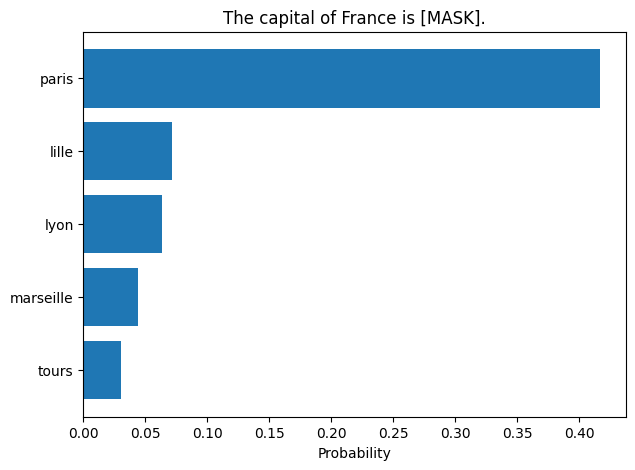

In [13]:
plot_top_tokens(top_tokens, top_probs, title=text)

Unsurprisingly, for the first example sentence *"The capital of France is [MASK]."* is indeed *"paris"*. While the other tokens are objectively wrong, they are still all French cities. Of course, for other examples, where there many other plausible tokens for `[MASK]` are possible, the probabilities of the different alternatives are likely to be much more similar. You are therefore encouraged to try one of the other example sentences or simply come up with your own examples to test.

Overall, when BERT makes sensible predictions for `[MASK]` tokens, such as `paris` for *"The capital of France is [MASK]."*, it shows that the model has learned more than surface statistics. To rank the right word highly, it must combine syntax (a noun is expected here), word semantics (what a capital is and how it relates to France), and some world knowledge, all from context alone. This indicates that its internal representations capture meaningful aspects of word semantics, which is what the MLM proxy task was designed to achieve. Plausible alternatives among the top candidates (e.g., other cities) further suggest that the model groups words by meaning, in line with the Distributional Hypothesis.

### Word Embedding Similarities

Recall that a key advantage of contextual embeddings over static ones is that the same word can receive different vectors depending on its context. A static model such as Word2Vec assigns *"bank"* a single vector, regardless of whether it appears in "river bank" or "bank account", so all its meanings are blended into one representation. BERT instead computes each token's embedding from the entire sentence, so *"bank"* gets distinct vectors in different contexts, which allows it to handle ambiguity (polysemy) and to represent meaning more precisely.

To test this, let's define five simple sentences, all containing the word *"bank"* but in more or less related contexts. Before continuing, think about which of the five occurrences of *"bank"* should be more similar to each other. For example, the second and third sentence use *"bank"* to refer to the financial institute, so their similarity should arguably be quite high.

In [14]:
sentences = ["He sat on the river bank.",
             "She deposited money at the bank.",
             "The bank approved my loan.",
             "The memory bank in my PC was broken.",
             "Fish swam near the muddy bank."]

We can now pass the list of sentences to our `embed()` method to get the embedding vectors for each token in all five sentences. We also use the tokenizer to give us the token ID for *"bank"*; we will need this in a moment to again find the position of *"bank"* in the sequence of output embeddings since we are only interested in that embedding (and not in the embedding of all other tokens).

In [15]:
enc, embeddings = embed(sentences, bare_model)

bank_id = tokenizer.convert_tokens_to_ids("bank")

Using the token ID for *"bank"*, we can now extract five embedding vectors of that word with respect to all five sentences and keep them in the list `vecs`.

In [16]:
vecs = []
for i in range(len(sentences)):
    # Find the position of the token "bank" in the sentence
    pos = (enc["input_ids"][i] == bank_id).nonzero()[0].item()
    # Extract the relevant embedding using the correct position
    vecs.append(embeddings[i, pos].cpu().numpy())

Using the [`cosine_similarity()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html) of the [scikit-learn](https://scikit-learn.org/) library, we can compute the cosine similarity between all pairs of embedding vectors.

In [17]:
similarities = cosine_similarity(vecs)

To visualize the result, we provide another auxiliary method `plot_heatmap()` to show all pairwise similarities &mdash; well, since the cosine similarity if symmatric, the heatmap only needs to show "half" of the results. Of course, the diagonal element represents the cosine similarity of an embedding with itself, thus yielding a similarity of $1.0$.

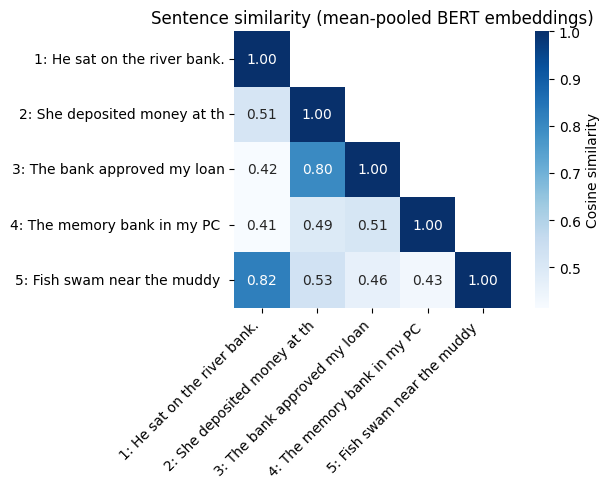

In [18]:
plot_heatmap(similarities, sentences)

From this plot we can see that the occurrences of *"bank"* are most similar between sentences 2 and 3 (both talking about the financial institute) and between sentences 1 and 5 (both talking about the strip of land near a body of water). Notice, however, that the other similarities are nowhere close to 0 as this would mean different meanings of *"bank"* must always have a completely different context. Given the ambiguity and flexibility of language, this is arbitrarily unlikely the case &mdash; the result here show it.

### Sentence Embedding Similarities

Since a sentence is made up of words, and each word embedding captures meaning, we can combine the word embeddings of a sentence into a single vector that represents the sentence as a whole. The simplest approach is to average (mean-pool) the token vectors, ignoring padding, or to use the `[CLS]` vector. Sentence vectors make it possible to compare texts numerically, for instance with cosine similarity, which enables simple applications such as semantic search and retrieval, duplicate or paraphrase detection, clustering and topic grouping of documents, recommending similar articles, and serving as input features for classifiers (e.g., sentiment analysis or spam detection).

The method `sentence_embedding()` below turns a batch of sentences into one fixed-size vector per sentence by mean-pooling BERT's token embeddings. It first calls `embed()` to get the tokenizer output and the contextual token vectors `embeddings` of shape `(batch, seq_len, 768)`. The attention mask (1 for real tokens, 0 for `[PAD]`) is expanded with `unsqueeze(-1)` to shape `(batch, seq_len, 1)` so it can be broadcast across the embedding dimension. Multiplying `embeddings` by this mask zeroes out the padding vectors, `.sum(1)` adds up the remaining token vectors over the sequence dimension, and dividing by `mask.sum(1)`, the number of real tokens, turns that sum into an average. The result, converted to a NumPy array of shape `(batch, 768)`, is one sentence vector per input

In [19]:
def sentence_embedding(sentences, model):
    enc, embeddings = embed(sentences, model)
    mask = enc["attention_mask"].unsqueeze(-1)
    return ((embeddings * mask).cpu().sum(1) / mask.cpu().sum(1)).cpu().numpy()

Side note: This simple implementation includes `[CLS]` and `[SEP]` tokens in the average. However, since both tokens appear in all sentences, they generally do not affect the results when to computing and comparing the similarity between pairs of sentences.

In [20]:
embeddings = sentence_embedding(sentences, bare_model)

similarities = cosine_similarity(embeddings)

We can now use `sentence_embedding()` to compute the embeddings for our five example sentences by averaging each sentence token embeddings. This gives us again a list of five embedding vectors for which we can compute their pairwise cosine similarities; and plot the result using `plot_heat_map()`.

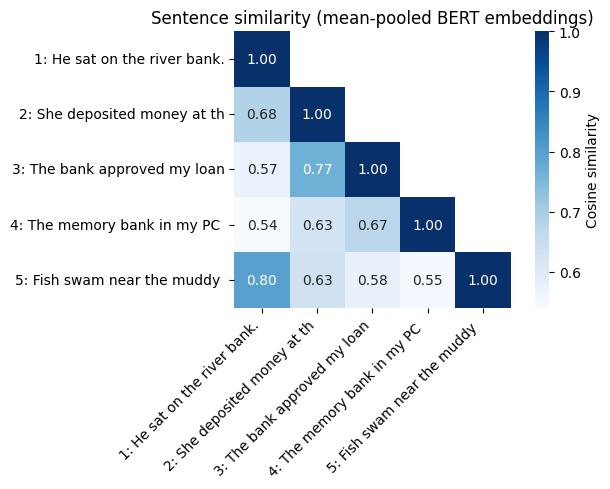

In [21]:
plot_heatmap(similarities, sentences)

Unsurprisingly, the results are similar to the ones we saw for comparing the individual embeddings for the *"bank"*. Sentences 2 and 3 as well as sentences 1 and 5 show the highest similarity since they talk about the "same thing" (i.e., the financial institute or the strip of land). Still, you can easily see how this approach can be used to find the most related sentences given input sentences by finding the sentences with the highest similarities.

Predicting plausible words for `[MASK]` tokens and comparing the similarity of example words or sentences is far from a proper evaluation. Such examples are small, hand-picked, and qualitative, and they cannot show how well the embeddings work in general (that requires benchmarks, probing tasks, or downstream performance). Still, they give a useful first impression: sensible masked-word predictions and higher similarity for related than for unrelated sentences show that BERT captures meaningful semantics, even though it was trained only on the proxy tasks of MLM and NSP without any labeled data.

---

## Discussion & What's Next?

### BERT Variants

While we talked about the (orginal) BERT model, nowadays BERT is better understood as a model family, because the original model leaves many design choices open, and each can be changed independently. Even the original release came in several sizes (BERT-base with 12 layers and 110M parameters, BERT-large with 24 layers and 340M), as well as cased, uncased, and multilingual versions. Because the encoder is general-purpose and fine-tuned for downstream tasks, researchers could keep the core idea and vary the parts that seemed suboptimal, which produced the many variants seen in practice. The variants differ mainly along a few key aspects: 

* **Learning objective(s)**, e.g. dropping NSP (RoBERTa), replacing it with sentence order prediction (ALBERT)
* **Training recipe**, such as more data, larger batches, and dynamic masking
* **Architecture**, e.g. parameter sharing, disentangled attention, or sparse attention for longer inputs;
* **The position encoding**, learned absolute versus static or relative schemes;
* **Efficiency and size**, through distillation or compression (DistilBERT, TinyBERT)
* **Vocabulary and language coverage**, such as WordPiece versus byte-level BPE or multilingual vocabularies.

The table below outlines some common BERT variants, but keep in mind that this list is far from comprehensive.

| Model | Main idea | Pre-training objective(s) | Key architectural / training changes | Size vs. BERT-base | Pros | Cons |
|---|---|---|---|---|---|---|
| **BERT** (2018) | Deep bidirectional encoder pre-trained on unlabeled text | MLM + NSP | Learned absolute positions, WordPiece (30k), static masking (10 duplicates), max length 512 | 110M params (base), 340M (large) | Strong general-purpose baseline; simple to fine-tune | NSP is a weak signal; undertrained; static masking; quadratic attention cost |
| **RoBERTa** (2019) | Same architecture, better training recipe | MLM only | Drops NSP, dynamic masking, much more data (about 160 GB), larger batches, longer training, byte-level BPE (50k) | About 125M (base) | Clearly better than BERT on most benchmarks with no architectural change | Higher training cost; still limited to 512 tokens |
| **ALBERT** (2019) | Reduce parameters and make training more efficient | MLM + sentence order prediction (SOP) | Factorized embedding matrix, cross-layer parameter sharing | About 12M (base) | Far fewer parameters, lower memory use, SOP is a harder coherence task | Compute is not reduced (same depth), so inference is not faster; sharing can limit capacity |
| **DistilBERT** (2019) | Compress BERT via knowledge distillation | MLM + distillation loss (+ cosine embedding loss) | Half the layers (6), token-type embeddings and pooler removed, student initialized from teacher layers | About 66M (40% smaller) | About 60% faster, retains about 97% of BERT's performance | Small performance drop; needs a trained teacher |
| **TinyBERT / MobileBERT** (2019) | Further compression for edge devices | Layer-wise distillation (TinyBERT), bottleneck architecture (MobileBERT) | Distill hidden states and attention maps, not just outputs | About 15M (TinyBERT-4L), about 25M (MobileBERT) | Very small and fast | Larger accuracy loss; more complex training |
| **DeBERTa** (2020) | Better modeling of position and content | MLM (plus enhanced mask decoder) | Disentangled attention (separate content and relative-position vectors), absolute positions added late | About 140M (base) | Strong on NLU benchmarks (SuperGLUE) | Slower and more complex attention |

Which variant fits best depends on the trade-off between accuracy, speed, memory, input length, and language or domain. However, a deeper discussion and comparison of these and more variants is way beyond this scope of this notebook introducing the original BERT model.

### Pretraining BERT

This notebook introduced BERT on a conceptual level: the Transformer encoder, the two learning objectives (MLM and NSP) and how they relate to the Distributional Hypothesis, the special tokens, the three types of IDs and their embeddings, and the preparation of a training sample. This is enough to understand *what* BERT does and *why* it is designed the way it is. However, a conceptual understanding only goes so far. Many details only become clear when implementing them: how masked and padded batches are actually constructed, how the loss mask and attention mask interact, how the MLM and NSP heads are attached to the encoder, and how the combined loss behaves during optimization. To fully understand the inner workings, it is therefore useful to train a BERT model from scratch, which is covered in a separate notebook.

### Finetuning BERT

It is important to acknowledge that MLM and NSP are **proxy tasks**: they are a means to an end, not the end itself. Nobody needs BERT to guess masked words or to decide whether two sentences are adjacent, since the answers are already known from the text. The value lies in what the network must learn along the way. To solve these tasks across billions of tokens, it has to encode syntax, semantics, and some world knowledge in its internal representations, so the byproduct is a set of rich, context-dependent embeddings. In practice, a pretrained BERT model is therefore typically used in one of two ways:

- **Feature extraction:** Convert words, sentences, or paragraphs into contextual embeddings (e.g. the final-layer token vectors, the `[CLS]` vector, or a pooled average over tokens) and use them as input for other models or methods, such as a logistic regression classifier, clustering, semantic search, or similarity computation. The pretrained weights stay frozen.
- **Fine-tuning:** Keep the pretrained encoder, attach a small task-specific head (e.g. a classification layer on `[CLS]` for sentiment or NLI, or a span-prediction head for question answering), and train the whole model, or part of it, on a labeled dataset for the target task. The pretrained weights serve as a strong initialization, so much less labeled data and training time are needed than when training from scratch.

While fine-tuning looks simple on paper &mdash; and as a conceptual idea, it is &mdash; in practice, the quality of the result depends on many details that are hard to appreciate from a conceptual description alone. Examples include choosing a suitable learning rate (too high can destroy the pretrained knowledge, a problem known as catastrophic forgetting), deciding whether to freeze or update the encoder layers, handling small labeled datasets and the instability across random seeds, choosing the sequence length and truncation strategy, dealing with class imbalance, and selecting which representation (`[CLS]`, pooled output, or token vectors) feeds the head. Different tasks also need different heads and input formats, such as sentence classification, sentence-pair tasks like NLI, token-level tasks like named entity recognition, and span prediction for question answering.

To understand how fine-tuning works and where the pitfalls lie, it is therefore best to fine-tune a pretrained model on several different tasks and observe how the choices affect the outcome. Again, this is covered in separate notebooks.

---

## Summary

This notebook introduced **BERT** at a conceptual level. It began with a recap of the goal of word embeddings, namely representing words as vectors that capture meaning through the contexts they appear in (the Distributional Hypothesis), and of the Transformer architecture on which BERT is built, in particular self-attention and the encoder layer with its feedforward network, residual connections, layer normalization, and dropout.

It then covered BERT's two original learning objectives and their purpose. **Masked Language Modeling (MLM)** corrupts about 15% of the input tokens (using the 80/10/10 rule) and trains the model to recover them from their bidirectional context, a direct implementation of the Distributional Hypothesis. **Next Sentence Prediction (NSP)** asks whether a second segment truly follows the first, which was intended to provide a sentence-level signal for tasks such as NLI and question answering. Both are proxy tasks: the goal is not to predict masked words or sentence adjacency, but to obtain rich contextual embeddings as a by-product.

Lastly, the notebook covered the BERT training setup: how to convert a corpus of documents into sentence pairs with random negatives for NSP, how to add the special tokens `[CLS]`, `[SEP]`, and `[PAD]`, how to apply MLM corruption, and how to build the **input representation** (token, segment, and position IDs, which are embedded, summed, normalized, and passed through dropout, together with an **attention mask**). It also showed the **output labels**, namely the MLM labels with loss masking and the NSP label, which feed the cross-entropy loss.

Learning about BERT is important because it marked a turning point in NLP: it established the pretrain-then-fine-tune paradigm, in which a single model trained on unlabeled text is reused for many downstream tasks. Many later models (RoBERTa, ALBERT, DistilBERT, ELECTRA, and others) are variants of BERT, and its ideas of self-supervised objectives, contextual embeddings, and special-token input formats carry over to modern language models. Understanding BERT therefore provides a solid foundation for understanding much of the current NLP landscape.

**Disclaimer:** This Jupyter Notebook contains content generated with the assistance of AI. While every effort has been made to review and validate the outputs, users should independently verify critical information before relying on it. The SELENE notebook repository is constantly evolving. We recommend downloading or pulling the latest version of this notebook from Github.